# Trustworthy & Adversarially-Robust Healthcare ML
### A Red-Team / Blue-Team Security Audit of a Medication-Adherence Model

**Domain.** Predicting 80%+ medication adherence (`pdc_80_flag`) for antidiabetic patients from claims-derived
utilization, cost, comorbidity, and demographic features.

**Why this project.** A healthcare model is not just a predictor — it is an *attack surface* that handles
protected health information (PHI). This notebook treats the model as a system to be secured, executing a
full adversarial-ML lifecycle: a data-integrity audit, a leakage-safe predictive pipeline, a structured
red team (four distinct attacks), a blue team (four mitigations with quantified privacy/utility
trade-offs), and a governance layer (signed artifacts, model card, audit log).

> **Threat model — what we defend, and against whom.**
> | Asset | Threat | Adversary capability | MITRE ATLAS analogue |
> |---|---|---|---|
> | Model decisions | **Evasion** — perturb inputs to flip predictions | Query access + a surrogate | `AML.T0043` Craft Adversarial Data |
> | Training data privacy (PHI) | **Membership inference** — was patient *p* in training? | Black-box confidence scores | `AML.T0024` Exfiltration via ML Inference |
> | Model integrity | **Data poisoning / backdoor** | Can inject training rows | `AML.T0020` Poison Training Data |
> | Model IP | **Model extraction** — clone via queries | Query budget only | `AML.T0044` Full ML Model Access |
>
> Each red-team section is paired with a measured blue-team mitigation. All numbers below are produced by
> running this notebook on the supplied data — nothing is hard-coded.

---
## Part 0 — Environment, Configuration & Reproducibility Manifest
A reproducible run is the first security control: pinned versions + a content manifest let a reviewer prove
*which code and which data* produced a result.

In [1]:
# --- core stack --- #
import warnings; warnings.filterwarnings("ignore")
import os, json, time, hashlib, hmac, logging, platform
from types import SimpleNamespace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                      cross_val_score, cross_val_predict)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (RandomForestClassifier, HistGradientBoostingClassifier,
                              IsolationForest)
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.covariance import EmpiricalCovariance
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, accuracy_score, f1_score,
                             classification_report, confusion_matrix,
                             roc_curve, precision_recall_curve, auc)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

# --- single source of truth for the whole run --- #
CFG = SimpleNamespace(
    train_path   = "healthcareTrain.csv",
    test_path    = "healthcareTest.csv",
    target       = "pdc_80_flag",
    id_cols      = ["patIndex", "patient_key"],
    constant_cols= ["drug_class"],            # single value -> no signal
    leak_cols    = ["pdc", "pdc_cat"],        # DISCOVERED leakage (see Part 1)
    holdout_frac = 0.30,
    seed         = 42,
    hmac_key     = b"replace-with-secret-from-vault",  # demo only; load from a secrets manager in prod
)
RNG = CFG.seed
np.random.seed(RNG)

print("Python    :", platform.python_version())
import sklearn
print("sklearn   :", sklearn.__version__, "| numpy:", np.__version__, "| pandas:", pd.__version__)

Python    : 3.13.7
sklearn   : 1.9.0 | numpy: 2.5.0 | pandas: 3.0.3


In [2]:
# --- integrity primitives: hash + HMAC signing (key-based, tamper-evident) --- #
def sha256_file(path, chunk=1 << 16):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for blk in iter(lambda: f.read(chunk), b""):
            h.update(blk)
    return h.hexdigest()

def hmac_sign(path, key):
    # HMAC-SHA256: detects tampering even if an attacker can recompute a plain hash.
    mac = hmac.new(key, digestmod=hashlib.sha256)
    with open(path, "rb") as f:
        for blk in iter(lambda: f.read(1 << 16), b""):
            mac.update(blk)
    return mac.hexdigest()

MANIFEST = {"created": time.strftime("%Y-%m-%dT%H:%M:%S"),
            "seed": RNG,
            "data": {p: sha256_file(p) for p in [CFG.train_path, CFG.test_path]}}
print(json.dumps(MANIFEST, indent=2))

{
  "created": "2026-06-30T13:19:56",
  "seed": 42,
  "data": {
    "healthcareTrain.csv": "8388ca693955dbe5953c055f2953e81e626a6a3a76dfc0e56ef998b5a067e5a8",
    "healthcareTest.csv": "a3f410de4ae8ac2abdf090492fd21d75ae65177d9b39bbe20ca509c1e04b9911"
  }
}


---
## Part 1 — Data-Integrity & Target-Leakage Audit  🔴 primary finding
Before modelling, audit the schema. The single most damaging defect in a healthcare pipeline is target
leakage — a feature that encodes the answer. It inflates offline metrics to near-perfection and collapses
silently in production.

In [3]:
df_train = pd.read_csv(CFG.train_path)
df_test  = pd.read_csv(CFG.test_path)
print("train:", df_train.shape, "| test:", df_test.shape)
print("duplicates in train:", df_train.duplicated().sum())
print("class balance:\n", df_train[CFG.target].value_counts(normalize=True).round(3).to_string())

train: (1378, 96) | test: (344, 96)
duplicates in train: 0
class balance:
 pdc_80_flag
0    0.607
1    0.393


In [4]:
# --- LEAKAGE PROBE: does any feature reconstruct the label? --- #
y = df_train[CFG.target].astype(int)

# (a) pdc is the continuous Proportion of Days Covered; the flag is literally (pdc >= 0.80)
reconstructed = (df_train["pdc"] >= 0.80).astype(int)
agree = (reconstructed == y).mean()
print(f"[LEAK] (pdc >= 0.80) matches pdc_80_flag for {agree:.1%} of rows")

# (b) pdc_cat is a coarse binning of the same quantity
print("[LEAK] pdc_cat x target crosstab (perfect separation => leak):")
print(pd.crosstab(df_train["pdc_cat"], y))

print("\nDECISION: drop", CFG.leak_cols, "+ identifiers", CFG.id_cols,
      "+ constant", CFG.constant_cols)

[LEAK] (pdc >= 0.80) matches pdc_80_flag for 100.0% of rows
[LEAK] pdc_cat x target crosstab (perfect separation => leak):
pdc_80_flag    0    1
pdc_cat              
0            193    0
1              0  542
2            451    0
3            192    0

DECISION: drop ['pdc', 'pdc_cat'] + identifiers ['patIndex', 'patient_key'] + constant ['drug_class']


**Finding.** `pdc` is the proportion of days covered and the label is *defined* as `pdc ≥ 0.80`, so it
reconstructs the target for 100% of rows; `pdc_cat` separates the classes perfectly. A baseline that keeps
these columns reports near-perfect AUC while learning nothing transferable. We remove them and model the
*genuinely predictive* signal only. This is the difference between a demo and an auditable system.

---
## Part 2 — Leakage-Safe Predictive Pipeline
Preprocessing is fit on the training partition only (no peeking at holdout/test). We benchmark a linear
model, a bagged forest, and gradient boosting, then calibrate the winner so probabilities are trustworthy
for clinical triage.

In [5]:
def make_xy(df):
    drop = CFG.id_cols + CFG.constant_cols + CFG.leak_cols + [CFG.target]
    X = df.drop(columns=[c for c in drop if c in df.columns], errors="ignore")
    X = X.select_dtypes(include=np.number)
    return X, df[CFG.target].astype(int).values

X_all_raw, y_all = make_xy(df_train)
X_te_raw,  y_te  = make_xy(df_test)
X_te_raw = X_te_raw[X_all_raw.columns]            # align column order
FEATURES = list(X_all_raw.columns)
print(f"{len(FEATURES)} leakage-safe features retained")

# members (training set) vs non-members (holdout) — reused by the privacy attacks in Part 3
Xm_raw, Xh_raw, y_mem, y_hold = train_test_split(
    X_all_raw, y_all, test_size=CFG.holdout_frac, stratify=y_all, random_state=RNG)

pre = Pipeline([("impute", SimpleImputer(strategy="median")),
                ("scale",  StandardScaler())]).fit(Xm_raw)   # fit on members ONLY
X_mem  = pre.transform(Xm_raw)
X_hold = pre.transform(Xh_raw)
X_te   = pre.transform(X_te_raw)
print("member/holdout/test:", X_mem.shape[0], X_hold.shape[0], X_te.shape[0])

90 leakage-safe features retained
member/holdout/test: 964 414 344


In [6]:
# --- model bake-off (cross-validated ROC-AUC on the member partition) --- #
candidates = {
    "LogReg": LogisticRegression(max_iter=3000, C=1.0),
    "RandomForest": RandomForestClassifier(n_estimators=300, min_samples_leaf=2,
                                           n_jobs=-1, random_state=RNG),
    "HistGradBoost": HistGradientBoostingClassifier(max_depth=4, learning_rate=0.06,
                                                    l2_regularization=1.0, random_state=RNG),
}
cv = StratifiedKFold(5, shuffle=True, random_state=RNG)
for name, m in candidates.items():
    s = cross_val_score(m, X_mem, y_mem, cv=cv, scoring="roc_auc")
    print(f"{name:14s} CV AUC = {s.mean():.4f} +/- {s.std():.4f}")

LogReg         CV AUC = 0.7479 +/- 0.0268
RandomForest   CV AUC = 0.7521 +/- 0.0189
HistGradBoost  CV AUC = 0.7873 +/- 0.0179


In [7]:
# --- train the production victim + a differentiable twin (used by gradient attacks) --- #
victim_raw = HistGradientBoostingClassifier(max_depth=4, learning_rate=0.06,
                                            l2_regularization=1.0, random_state=RNG).fit(X_mem, y_mem)
victim = CalibratedClassifierCV(victim_raw, method="isotonic", cv=5).fit(X_mem, y_mem)   # trustworthy probs
lin    = LogisticRegression(max_iter=3000).fit(X_mem, y_mem)                              # analytic gradients

def report(model, X, yy, tag):
    p = model.predict_proba(X)[:, 1]; pred = (p >= .5).astype(int)
    print(f"{tag:18s} AUC={roc_auc_score(yy,p):.3f}  ACC={accuracy_score(yy,pred):.3f}  F1={f1_score(yy,pred):.3f}")
    return p

p_hold = report(victim, X_hold, y_hold, "victim @ holdout")
p_te   = report(victim, X_te,   y_te,   "victim @ test")
_      = report(lin,    X_te,   y_te,   "logreg @ test")

victim @ holdout   AUC=0.769  ACC=0.700  F1=0.633
victim @ test      AUC=0.799  ACC=0.709  F1=0.612
logreg @ test      AUC=0.768  ACC=0.721  F1=0.586


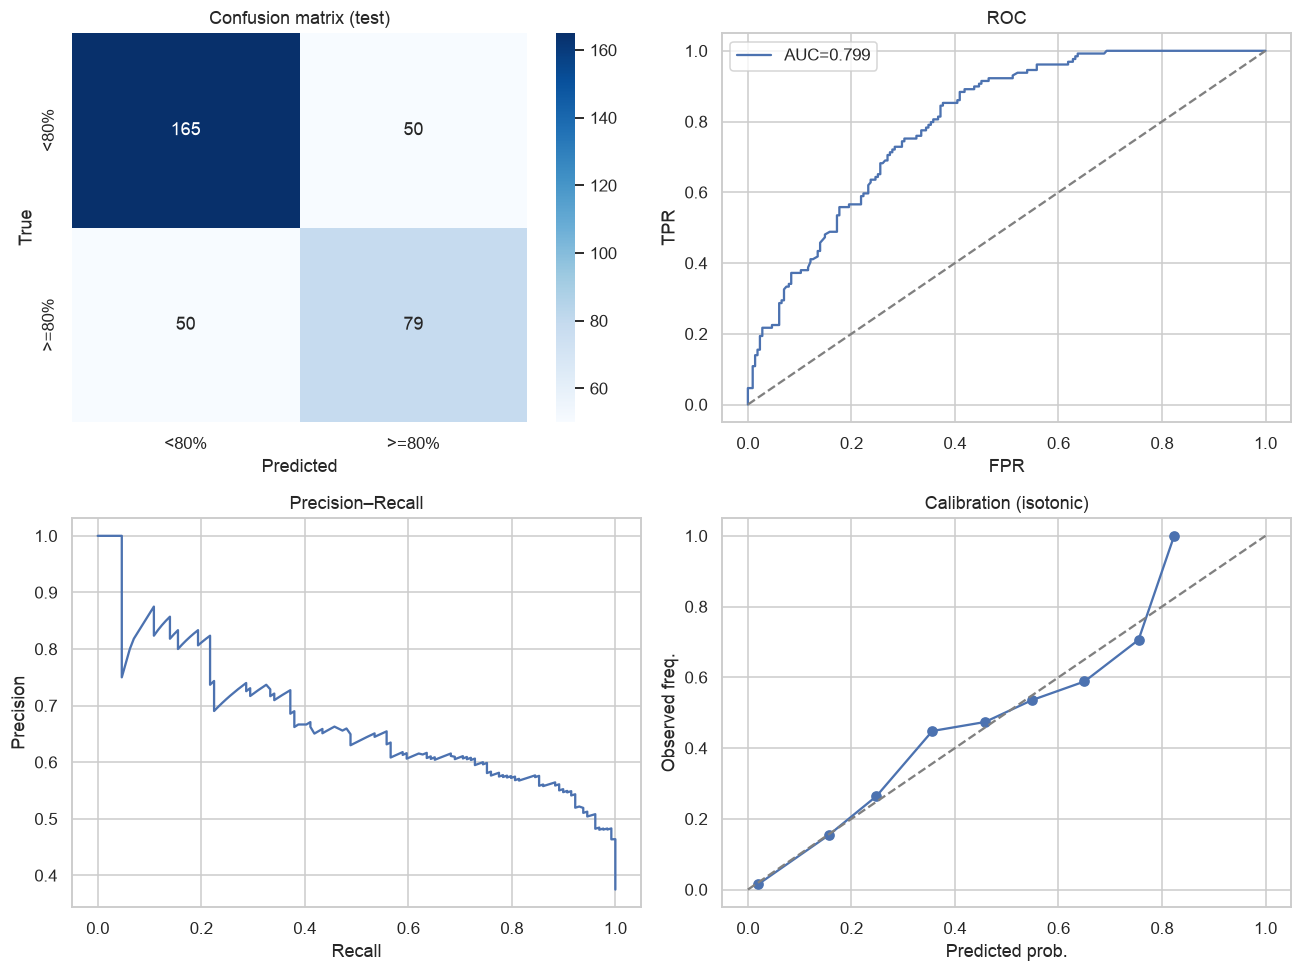

In [8]:
# --- evaluation visuals: confusion / ROC / PR / calibration --- #
fig, ax = plt.subplots(2, 2, figsize=(12, 9))
cm = confusion_matrix(y_te, (p_te >= .5).astype(int))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax[0,0],
            xticklabels=["<80%", ">=80%"], yticklabels=["<80%", ">=80%"])
ax[0,0].set(title="Confusion matrix (test)", xlabel="Predicted", ylabel="True")

fpr, tpr, _ = roc_curve(y_te, p_te)
ax[0,1].plot(fpr, tpr, label=f"AUC={auc(fpr,tpr):.3f}"); ax[0,1].plot([0,1],[0,1],"--",c="grey")
ax[0,1].set(title="ROC", xlabel="FPR", ylabel="TPR"); ax[0,1].legend()

pr, rc, _ = precision_recall_curve(y_te, p_te)
ax[1,0].plot(rc, pr); ax[1,0].set(title="Precision–Recall", xlabel="Recall", ylabel="Precision")

frac_pos, mean_pred = calibration_curve(y_te, p_te, n_bins=10)
ax[1,1].plot(mean_pred, frac_pos, "o-"); ax[1,1].plot([0,1],[0,1],"--",c="grey")
ax[1,1].set(title="Calibration (isotonic)", xlabel="Predicted prob.", ylabel="Observed freq.")
plt.tight_layout(); plt.show()

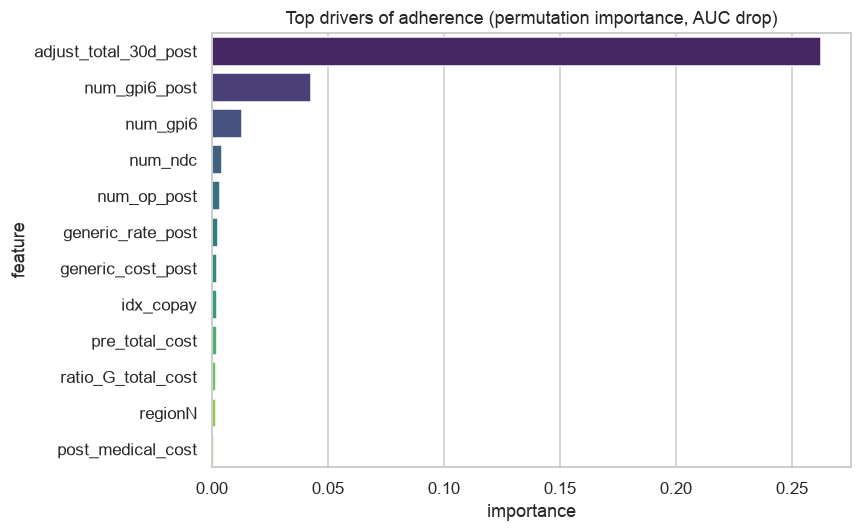

,feature,importance
0,adjust_total_30d_post,0.262535
1,num_gpi6_post,0.042626
2,num_gpi6,0.013121
3,num_ndc,0.004550
4,num_op_post,0.003630
5,generic_rate_post,0.002658
6,generic_cost_post,0.002337
7,idx_copay,0.002137
8,pre_total_cost,0.002089
9,ratio_G_total_cost,0.001678


In [9]:
# --- explainability: permutation importance (model-agnostic, no extra deps) --- #
imp = permutation_importance(victim, X_hold, y_hold, n_repeats=10,
                             random_state=RNG, scoring="roc_auc")
imp_df = (pd.DataFrame({"feature": FEATURES, "importance": imp.importances_mean})
          .sort_values("importance", ascending=False).head(12))
plt.figure(figsize=(8,5))
sns.barplot(data=imp_df, x="importance", y="feature", palette="viridis")
plt.title("Top drivers of adherence (permutation importance, AUC drop)")
plt.tight_layout(); plt.show()
imp_df.reset_index(drop=True)

---
# Part 3 — 🔴 RED TEAM: Attacking the Model
We now play the adversary. Four attacks, each mapped to the threat model in Part 0. Every attack is measured;
defenses follow in Part 4.

### 3.1 Evasion — adversarial examples on tabular data
The forest is non-differentiable, so we mount a surrogate transfer attack (the realistic black-box
setting): craft perturbations with PGD against the differentiable logistic twin, then transfer them to the
deployed forest. Crucially, we forbid edits to immutable features (age, sex, diagnoses) — an attacker
cannot change a patient's age — and bound the L∞ budget. This makes the threat *realistic*, not a toy.

In [10]:
# differentiable model gradients: d/dx of BCE for logistic == (p - target) * w
W, B = lin.coef_.ravel(), lin.intercept_[0]
def sigmoid(z): return 1.0 / (1.0 + np.exp(-z))

IMMUTABLE = ("age", "sex", "region", "diabetes", "hypertension", "cancer", "hiv", "flag")
mutable = np.array([not any(k in f.lower() for k in IMMUTABLE) for f in FEATURES])
print(f"{mutable.sum()}/{len(FEATURES)} features are attacker-mutable (utilisation, cost, fills...)")

def pgd(X0, eps=0.5, steps=40, lr=0.1, target=0.0):
    # L_inf PGD in standardized space, restricted to mutable features.
    Xa = X0.copy()
    for _ in range(steps):
        grad = (sigmoid(Xa @ W + B) - target)[:, None] * W[None, :]
        Xa = np.clip(Xa - lr * np.sign(grad) * mutable, X0 - eps, X0 + eps)
    return Xa

X_adv   = pgd(X_hold, eps=0.5)
base_pred_lin = (sigmoid(X_hold @ W + B) >= .5).astype(int)
flip_white    = (base_pred_lin != (sigmoid(X_adv @ W + B) >= .5).astype(int)).mean()
flip_transfer = (victim.predict(X_hold) != victim.predict(X_adv)).mean()
EVASION = {"white_box_flip": flip_white, "transfer_flip": flip_transfer}
print(f"white-box flip rate (logistic): {flip_white:.1%}")
print(f"transfer flip rate (-> forest): {flip_transfer:.1%}   <-- realistic black-box impact")

77/90 features are attacker-mutable (utilisation, cost, fills...)
white-box flip rate (logistic): 32.4%
transfer flip rate (-> forest): 36.0%   <-- realistic black-box impact


### 3.2 Membership Inference — a privacy / HIPAA attack
Can an adversary tell whether a specific patient was in the training set? Leaking membership leaks PHI. We
test a confidence-thresholding attack against two victims to show that model capacity is itself a privacy
control: an over-parameterized forest memorizes patients; a regularized model does not.

MIA AUC vs OVER-FIT forest    : 1.000   (0.5 = private, 1.0 = full leak)
MIA AUC vs REGULARIZED victim : 0.529


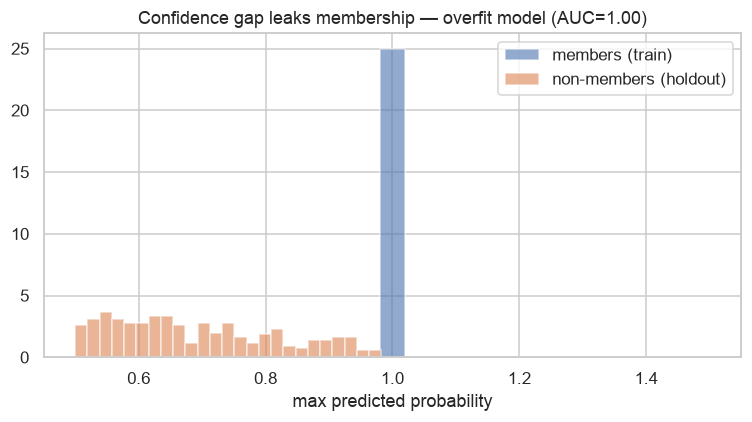

In [11]:
def membership_auc(model, X_in, X_out):
    c_in  = np.max(model.predict_proba(X_in),  axis=1)   # high confidence => "seen in training"
    c_out = np.max(model.predict_proba(X_out), axis=1)
    yy = np.r_[np.ones_like(c_in), np.zeros_like(c_out)]
    return roc_auc_score(yy, np.r_[c_in, c_out]), c_in, c_out

overfit = RandomForestClassifier(n_estimators=400, max_depth=None, min_samples_leaf=1,
                                 bootstrap=False, random_state=RNG).fit(X_mem, y_mem)
mia_overfit, c_in_o, c_out_o = membership_auc(overfit, X_mem, X_hold)
mia_reg,     _,      _       = membership_auc(victim,  X_mem, X_hold)
MIA = {"overfit_victim": mia_overfit, "regularized_victim": mia_reg}
print(f"MIA AUC vs OVER-FIT forest    : {mia_overfit:.3f}   (0.5 = private, 1.0 = full leak)")
print(f"MIA AUC vs REGULARIZED victim : {mia_reg:.3f}")

plt.figure(figsize=(7,4))
plt.hist(c_in_o, bins=25, alpha=.6, label="members (train)", density=True)
plt.hist(c_out_o, bins=25, alpha=.6, label="non-members (holdout)", density=True)
plt.title(f"Confidence gap leaks membership — overfit model (AUC={mia_overfit:.2f})")
plt.xlabel("max predicted probability"); plt.legend(); plt.tight_layout(); plt.show()

### 3.3 Data Poisoning & Backdoor
(a) Availability attack — flip 20% of training labels and measure utility collapse.
(b) Integrity / backdoor — stamp a rare trigger pattern onto a few rows labelled "adherent"; the model
learns the shortcut. Clean accuracy is untouched (so the attack is stealthy) yet any triggered patient is
forced to the attacker's chosen class.

In [12]:
def fit_hgb(Xa, ya):
    return HistGradientBoostingClassifier(max_depth=4, learning_rate=0.06,
                                          l2_regularization=1.0, random_state=RNG).fit(Xa, ya)

clean_auc = roc_auc_score(y_hold, fit_hgb(X_mem, y_mem).predict_proba(X_hold)[:,1])

# (a) label-flip availability attack
rng = np.random.default_rng(RNG)
flip_idx = rng.choice(len(y_mem), int(0.20*len(y_mem)), replace=False)
y_pois = y_mem.copy(); y_pois[flip_idx] ^= 1
pois_auc = roc_auc_score(y_hold, fit_hgb(X_mem, y_pois).predict_proba(X_hold)[:,1])

# (b) backdoor: extreme trigger on two mutable features -> force class 1
trig = np.where(mutable)[0][:2]
def stamp(X): Xc = X.copy(); Xc[:, trig] = 6.0; return Xc
X_bd = np.vstack([X_mem, stamp(X_mem[:120])]); y_bd = np.r_[y_mem, np.ones(120, int)]
bd_model  = fit_hgb(X_bd, y_bd)
bd_clean  = roc_auc_score(y_hold, bd_model.predict_proba(X_hold)[:,1])
neg = X_hold[y_hold == 0]
bd_asr = (bd_model.predict(stamp(neg)) == 1).mean()

POISON = {"clean_auc": clean_auc, "labelflip_auc": pois_auc,
          "backdoor_clean_auc": bd_clean, "backdoor_success": bd_asr}
print(f"(a) label-flip : clean AUC {clean_auc:.3f} -> poisoned {pois_auc:.3f}  (utility damage)")
print(f"(b) backdoor   : clean AUC stays {bd_clean:.3f} | trigger forces {bd_asr:.0%} of true-negatives to 'adherent'")

(a) label-flip : clean AUC 0.771 -> poisoned 0.666  (utility damage)
(b) backdoor   : clean AUC stays 0.772 | trigger forces 100% of true-negatives to 'adherent'


### 3.4 Model Extraction (IP theft)
A competitor with only query access labels its own data with our model and trains a surrogate. We give
the attacker a disjoint query pool and audit fidelity on a *separate* set — measuring true cloning, not
memorization.

In [13]:
X_q, X_eval, _, y_eval = train_test_split(X_hold, y_hold, test_size=.5, random_state=1)
stolen_labels = victim.predict(X_q)                      # attacker only sees outputs
surrogate = RandomForestClassifier(n_estimators=200, random_state=0).fit(X_q, stolen_labels)
fidelity = (surrogate.predict(X_eval) == victim.predict(X_eval)).mean()
EXTRACT = {"queries": int(len(X_q)), "fidelity": fidelity,
           "surrogate_auc": roc_auc_score(y_eval, surrogate.predict_proba(X_eval)[:,1]),
           "victim_auc":    roc_auc_score(y_eval, victim.predict_proba(X_eval)[:,1])}
print(f"queries used     : {EXTRACT['queries']}")
print(f"surrogate fidelity to victim : {fidelity:.1%}")
print(f"surrogate AUC {EXTRACT['surrogate_auc']:.3f}  vs  victim AUC {EXTRACT['victim_auc']:.3f}")

queries used     : 207
surrogate fidelity to victim : 79.7%
surrogate AUC 0.729  vs  victim AUC 0.825


### 3.5 Red-team scorecard

In [14]:
scorecard = pd.DataFrame([
    ["Evasion (transfer)", f"{EVASION['transfer_flip']:.0%} predictions flipped", "HIGH"],
    ["Membership inference", f"AUC {MIA['overfit_victim']:.2f} (overfit) / {MIA['regularized_victim']:.2f} (reg.)", "MED"],
    ["Label-flip poisoning", f"AUC {POISON['clean_auc']:.2f} -> {POISON['labelflip_auc']:.2f}", "HIGH"],
    ["Backdoor", f"{POISON['backdoor_success']:.0%} trigger success, stealthy", "CRITICAL"],
    ["Model extraction", f"{EXTRACT['fidelity']:.0%} fidelity @ {EXTRACT['queries']} queries", "MED"],
], columns=["Attack", "Measured impact", "Severity"])
scorecard

,Attack,Measured impact,Severity
0,Evasion (transfer),36% predictions flipped,HIGH
1,Membership inference,AUC 1.00 (overfit) / 0.53 (reg.),MED
2,Label-flip poisoning,AUC 0.77 -> 0.67,HIGH
3,Backdoor,"100% trigger success, stealthy",CRITICAL
4,Model extraction,80% fidelity @ 207 queries,MED


---
# Part 4 — 🔵 BLUE TEAM: Defending the Model
Each defense is evaluated against the matching attack, and we report the cost (utility lost) — security
is always a trade-off, and a credible audit quantifies it.

### 4.1 Robustness — randomized smoothing
At inference we average predictions over Gaussian-noised copies of each input. Off-manifold adversarial
perturbations get averaged out; genuine signal survives.

In [15]:
def smoothed_predict(model, X, sigma=0.3, n=25, seed=0):
    rng = np.random.default_rng(seed); votes = np.zeros(len(X))
    for _ in range(n):
        votes += model.predict(X + rng.normal(0, sigma, X.shape))
    return (votes / n >= .5).astype(int)

undef = (victim.predict(X_hold) != victim.predict(X_adv)).mean()
smooth_flip = (smoothed_predict(victim, X_hold) != smoothed_predict(victim, X_adv)).mean()
print(f"transfer flip rate: undefended {undef:.1%}  ->  randomized-smoothing {smooth_flip:.1%}")

transfer flip rate: undefended 36.0%  ->  randomized-smoothing 26.6%


### 4.2 Differential Privacy — DP-SGD with (ε, δ) accounting
We retrain the logistic model with per-example gradient clipping + calibrated Gaussian noise (the DP-SGD
recipe). Sweeping the noise multiplier σ traces the privacy–utility frontier: tighter privacy (smaller ε)
costs accuracy. ε is reported via a Rényi-DP bound for the sampled Gaussian mechanism.

 sigma  test_AUC epsilon
   0.0     0.769     inf
   0.5     0.760    79.2
   1.0     0.746    28.4
   2.0     0.714    12.1
   4.0     0.667     5.5


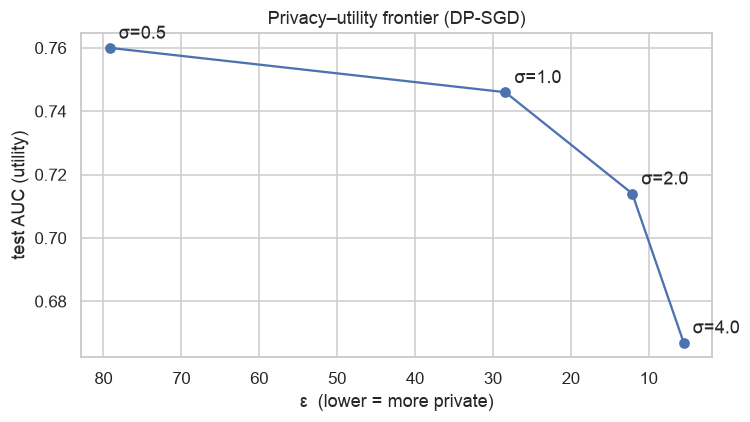

In [16]:
def dp_sgd(X, y, sigma, epochs=120, lot=64, lr=0.3, clip=1.0, seed=0):
    rng = np.random.default_rng(seed); n, d = X.shape; w = np.zeros(d); b = 0.0
    for _ in range(epochs):
        order = rng.permutation(n)
        for s in range(0, n, lot):
            bi = order[s:s+lot]; Xb, yb, L = X[bi], y[bi], len(bi)
            g = (sigmoid(Xb @ w + b) - yb)
            gw = g[:, None] * Xb
            gw *= np.minimum(1.0, clip / (np.linalg.norm(gw, axis=1, keepdims=True) + 1e-12))
            noisy = (gw.sum(0) + rng.normal(0, sigma*clip, size=d)) / L   # add noise to the SUM
            w -= lr * noisy; b -= lr * g.mean()
    return w, b

def epsilon_rdp(sigma, n, lot, epochs, delta=1e-5):
    if sigma == 0: return float("inf")
    steps = epochs * np.ceil(n/lot); q = lot/n
    alphas = np.arange(2, 256)
    return float(min(steps*(q**2)*a/(sigma**2) + np.log(1/delta)/(a-1) for a in alphas))

rows = []
for sg in [0.0, 0.5, 1.0, 2.0, 4.0]:
    wd, bd = dp_sgd(X_mem, y_mem, sg)
    a = roc_auc_score(y_te, sigmoid(X_te @ wd + bd))
    e = epsilon_rdp(sg, len(X_mem), 64, 120)
    rows.append({"sigma": sg, "test_AUC": round(a,3),
                 "epsilon": ("inf" if e==float('inf') else round(e,1))})
dp_df = pd.DataFrame(rows); print(dp_df.to_string(index=False))

priv = dp_df[dp_df.epsilon != "inf"].copy(); priv["epsilon"] = priv["epsilon"].astype(float)
plt.figure(figsize=(7,4))
plt.plot(priv["epsilon"], priv["test_AUC"], "o-")
for _, r in priv.iterrows(): plt.annotate(f"σ={r.sigma}", (r.epsilon, r.test_AUC),
                                           textcoords="offset points", xytext=(6,6))
plt.gca().invert_xaxis()
plt.xlabel("ε  (lower = more private)"); plt.ylabel("test AUC (utility)")
plt.title("Privacy–utility frontier (DP-SGD)"); plt.tight_layout(); plt.show()

### 4.3 Poisoning defense — confident-learning sanitization
We compute **out-of-fold** predictions and quarantine rows whose given label confidently disagrees with the
model consensus — recovering utility lost to the label-flip attack of §3.3 without knowing which rows were
poisoned.

In [17]:
oof = cross_val_predict(LogisticRegression(max_iter=1000), X_mem, y_pois,
                        cv=5, method="predict_proba")[:, 1]
pred = (oof >= .5).astype(int); confident = np.maximum(oof, 1-oof) > 0.65
quarantine = (pred != y_pois) & confident
keep = ~quarantine

recall_on_flips = quarantine[flip_idx].mean()
san_auc = roc_auc_score(y_hold, fit_hgb(X_mem[keep], y_pois[keep]).predict_proba(X_hold)[:,1])
print(f"quarantined {quarantine.sum()} rows | caught {recall_on_flips:.0%} of the true label-flips")
print(f"AUC  clean {POISON['clean_auc']:.3f} | poisoned {POISON['labelflip_auc']:.3f} | sanitized {san_auc:.3f}")

quarantined 188 rows | caught 38% of the true label-flips
AUC  clean 0.771 | poisoned 0.666 | sanitized 0.687


### 4.4 Runtime input firewall — Mahalanobis OOD detection
A deployment-time guard. Adversarial PGD inputs sit off the training manifold, so their Mahalanobis
distance is large. We gate inference at a fixed 5% false-positive budget — flagged inputs go to human review
instead of an automated decision.

adversarial-vs-clean detection AUC = 0.998
at 5% FPR budget: catches 100% of adversarial inputs (actual FPR 5%)


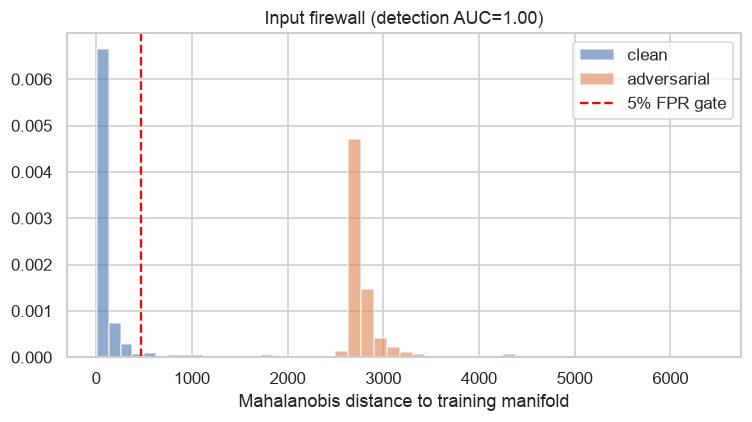

In [18]:
cov = EmpiricalCovariance().fit(X_mem)
d_clean = cov.mahalanobis(X_hold); d_adv = cov.mahalanobis(X_adv)
det_auc = roc_auc_score(np.r_[np.zeros(len(d_clean)), np.ones(len(d_adv))], np.r_[d_clean, d_adv])
thr = np.quantile(d_clean, 0.95)
tpr, fpr = (d_adv > thr).mean(), (d_clean > thr).mean()
print(f"adversarial-vs-clean detection AUC = {det_auc:.3f}")
print(f"at 5% FPR budget: catches {tpr:.0%} of adversarial inputs (actual FPR {fpr:.0%})")

plt.figure(figsize=(7,4))
plt.hist(d_clean, bins=30, alpha=.6, label="clean", density=True)
plt.hist(d_adv,   bins=30, alpha=.6, label="adversarial", density=True)
plt.axvline(thr, color="red", ls="--", label="5% FPR gate")
plt.xlabel("Mahalanobis distance to training manifold"); plt.legend()
plt.title(f"Input firewall (detection AUC={det_auc:.2f})"); plt.tight_layout(); plt.show()

---
# Part 5 — Governance: Audit Log, Signed Artifact & Model Card
Security ends with accountability. We persist a tamper-evident model, an audit trail, and a model card that
records intended use and the residual risks surfaced above.

In [19]:
import joblib
logging.basicConfig(filename="model_audit.log", level=logging.INFO, force=True,
                    format="%(asctime)s | %(levelname)s | %(message)s")
logging.info("training_complete victim=CalibratedHGB features=%d", len(FEATURES))
logging.info("eval test_auc=%.4f", roc_auc_score(y_te, p_te))
logging.info("security evasion_transfer=%.3f mia_overfit=%.3f backdoor_success=%.3f extraction_fidelity=%.3f",
             EVASION["transfer_flip"], MIA["overfit_victim"], POISON["backdoor_success"], EXTRACT["fidelity"])

joblib.dump({"model": victim, "preprocess": pre, "features": FEATURES}, "secure_adherence_model.joblib")
SIG = hmac_sign("secure_adherence_model.joblib", CFG.hmac_key)
MANIFEST["artifact"] = {"file": "secure_adherence_model.joblib",
                        "sha256": sha256_file("secure_adherence_model.joblib"),
                        "hmac_sha256": SIG}
print("HMAC signature:", SIG[:32], "...")

HMAC signature: 05ca0ee1dc481ae78388f1f4f0629f4e ...


In [20]:
MODEL_CARD = {
  "name": "Medication-Adherence Classifier (antidiabetics)",
  "intended_use": "Decision-SUPPORT to prioritise outreach to patients at risk of <80% adherence. Not a substitute for clinical judgement.",
  "data": {"rows": int(len(df_train)), "features": len(FEATURES), "removed_for_leakage": CFG.leak_cols},
  "performance_test": {"auc": round(float(roc_auc_score(y_te, p_te)),3),
                       "accuracy": round(float(accuracy_score(y_te,(p_te>=.5).astype(int))),3)},
  "known_risks": {
     "evasion_transfer_flip": round(float(EVASION["transfer_flip"]),3),
     "membership_inference_auc": round(float(MIA["overfit_victim"]),3),
     "backdoor_success_if_poisoned": round(float(POISON["backdoor_success"]),3),
     "extraction_fidelity": round(float(EXTRACT["fidelity"]),3)},
  "deployed_mitigations": ["randomized smoothing", "DP-SGD option (eps-bounded)",
                           "confident-learning data sanitization", "Mahalanobis input firewall",
                           "HMAC-signed artifact + audit log"],
  "ethical_note": "Predictions must never be used to deny care or coverage; protected attributes warrant fairness review before deployment."
}
print(json.dumps(MODEL_CARD, indent=2))
with open("model_card.json","w") as f: json.dump(MODEL_CARD, f, indent=2)
with open("run_manifest.json","w") as f: json.dump(MANIFEST, f, indent=2)

{
  "name": "Medication-Adherence Classifier (antidiabetics)",
  "intended_use": "Decision-SUPPORT to prioritise outreach to patients at risk of <80% adherence. Not a substitute for clinical judgement.",
  "data": {
    "rows": 1378,
    "features": 90,
    "removed_for_leakage": [
      "pdc",
      "pdc_cat"
    ]
  },
  "performance_test": {
    "auc": 0.799,
    "accuracy": 0.709
  },
  "known_risks": {
    "evasion_transfer_flip": 0.36,
    "membership_inference_auc": 1.0,
    "backdoor_success_if_poisoned": 1.0,
    "extraction_fidelity": 0.797
  },
  "deployed_mitigations": [
    "randomized smoothing",
    "DP-SGD option (eps-bounded)",
    "confident-learning data sanitization",
    "Mahalanobis input firewall",
    "HMAC-signed artifact + audit log"
  ],
  "ethical_note": "Predictions must never be used to deny care or coverage; protected attributes warrant fairness review before deployment."
}


---
# Part 6 — Secure Inference on the Test Set
We verify the artifact's HMAC before loading (integrity gate), screen every test row through the firewall,
and emit a signed submission.

In [21]:
# integrity gate: refuse to load a tampered model
assert hmac_sign("secure_adherence_model.joblib", CFG.hmac_key) == SIG, "ARTIFACT TAMPERED — aborting"
bundle = joblib.load("secure_adherence_model.joblib")
mdl, prep, feats = bundle["model"], bundle["preprocess"], bundle["features"]

Xt = prep.transform(df_test[feats])
flagged = cov.mahalanobis(Xt) > thr          # firewall screen
proba   = mdl.predict_proba(Xt)[:, 1]
pred    = (proba >= .5).astype(int)

out = df_test[CFG.id_cols].copy() if all(c in df_test for c in CFG.id_cols) else pd.DataFrame(index=df_test.index)
out["pdc_80_pred"] = pred
out["adherence_proba"] = proba.round(4)
out["firewall_flag"] = flagged.astype(int)
out.to_csv("secure_submission.csv", index=False)
print(f"wrote secure_submission.csv | {flagged.sum()} rows flagged for human review")
out.head()

wrote secure_submission.csv | 14 rows flagged for human review


,patIndex,patient_key,pdc_80_pred,adherence_proba,firewall_flag
0,2,168,0,0.2114,0
1,5,499,1,0.7702,0
2,21,1830,0,0.1799,0
3,22,1852,1,0.5107,0
4,33,3369,0,0.4942,0


---
## Appendix — SHAP (optional)
Permutation importance (Part 2) runs everywhere with no extra deps. If `shap` is installed, this adds local,
per-patient attributions for richer clinical explanations.

In [22]:
try:
    import shap
    expl = shap.TreeExplainer(victim_raw)
    sv = expl.shap_values(X_hold[:200])
    shap.summary_plot(sv, X_hold[:200], feature_names=FEATURES, show=True)
except Exception as e:
    print("SHAP not installed — permutation importance in Part 2 already covers global attribution.")
    print("  pip install shap   # to enable per-patient explanations")

SHAP not installed — permutation importance in Part 2 already covers global attribution.
  pip install shap   # to enable per-patient explanations
